In [1]:
packages <- c("dplyr", "stringr", "ggplot2", "platetools", "patchwork")
for (package in packages) {
    suppressWarnings(
        suppressPackageStartupMessages(
            library(package, character.only = TRUE)
        )
    )
}

In [2]:
git_root <- system("git rev-parse --show-toplevel", intern = TRUE)

In [ ]:
platemap_figure_file_path <- file.path(git_root,"figures/drugs_figure/platemap_figure.png")
if (!file.exists(platemap_figure_file_path)) {
    dir.create(dirname(platemap_figure_file_path), recursive = TRUE)
}
platemap_file_path <- file.path(git_root,"config/platemaps/platemap2.csv")
platemap <- read.csv(platemap_file_path, stringsAsFactors = FALSE)

In [4]:
# Add leading zeros if needed (uncomment the commented code in your notebook)
platemap <- platemap %>%
  mutate(well_position = str_replace(WellPosition, "([A-H])([1-9])$", "\\10\\2"))
platemap$dose_unit <- paste0(platemap$Dose, " ", platemap$Unit)
head(platemap)


,WellRow,WellCol,WellPosition,Treatment,Dose,Unit,well_position,dose_unit
,<chr>,<int>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>
1,B,2,B2,ARV-825,1,uM,B02,1 uM
2,C,2,C2,Staurosporine,10,nM,C02,10 nM
3,D,2,D2,Digoxin,1,uM,D02,1 uM
4,E,2,E2,Digoxin,1,uM,E02,1 uM
5,F,2,F2,Onalespib,1,uM,F02,1 uM
6,G,2,G2,Staurosporine,10,nM,G02,10 nM


Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the platetools package.
  Please report the issue at <https://github.com/swarchal/platetools/issues>.”


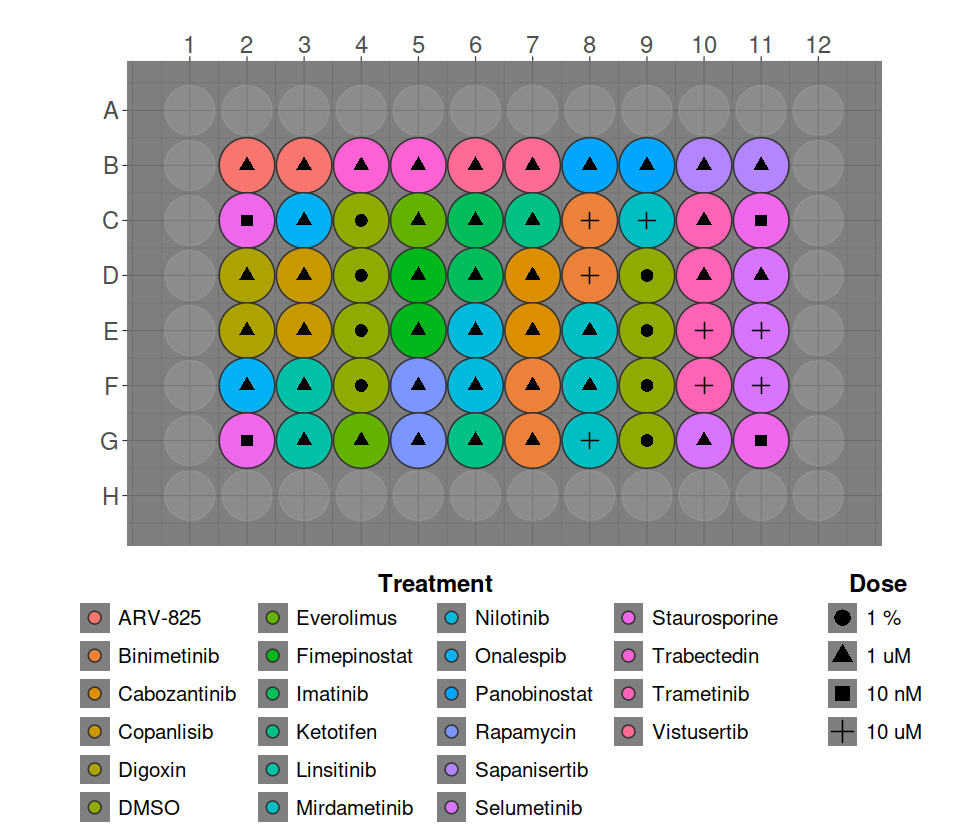

In [5]:
width <- 8
height <- 7
options(repr.plot.width = width, repr.plot.height = height)
font_size <- 16
axis_text_size <- font_size - 2
# Now create the plot
platemap_figure <- (
    platetools::raw_map(
        data = platemap$Treatment,
        well = platemap$well_position,
        # shape = platemap$dose_unit,
        plate = 96,
        size = 15
    )
    + theme_dark()

    + theme(
        plot.title = element_text(size = 15, hjust = 0.5, face = "bold"),
        axis.text = element_text(size = axis_text_size),
        legend.position = "bottom",
        legend.title.position = "top",
        # make the legend go from left to right,
        legend.text = element_text(size = axis_text_size-2),
        legend.title = element_text(size = axis_text_size, face = "bold", hjust = 0.5)
        
        ) 
    + ggplot2::geom_point(aes(shape = platemap$dose_unit), size = 3)
    + ggplot2::scale_shape_discrete(name = "Dose")
    # make the legend three columns
    + guides(
        fill  = guide_legend(
            ncol = 4,
            override.aes = list(size = 3),
            title = "Treatment",
            order = 1,
            label.position = "right"
        ),
        shape = guide_legend(
            ncol = 1,
            override.aes = list(size = 4),
            title = "Dose",
            order = 2,
            label.position = "right"
        )
    )

)
ggsave(
    filename = platemap_figure_file_path,
    plot = platemap_figure,
    width = width,
    height = height,
    units = "in",
    dpi = 600
)
platemap_figure